# Praktikum Minggu 12 — Predictive Mining for Time-Series Data

Nomor 1 — Membaca dan Menampilkan Dataset

In [1]:
import pandas as pd 

dataset = pd.read_csv('transaction.csv')
print(dataset)

       InvoiceNo  StockCode  Qty      InvoiceDate  CustomerID  \
0         537626      22725  830  12/7/2010 14:57       12347   
1         537626      22729  948  12/7/2010 14:57       12347   
2         537626      22195  695  12/7/2010 14:57       12347   
3         542237      22725  636  1/26/2011 14:30       12347   
4         542237      22729  536  1/26/2011 14:30       12347   
...          ...        ...  ...              ...         ...   
10541     543911      21700  455  2/14/2011 12:46       17829   
10542     543911      22111  578  2/14/2011 12:46       17829   
10543     543911      22112  163  2/14/2011 12:46       17829   
10544     564428      23296  545  8/25/2011 11:27       17844   
10545     564428      23294  643  8/25/2011 11:27       17844   

                    Country  
0                   Iceland  
1                   Iceland  
2                   Iceland  
3                   Iceland  
4                   Iceland  
...                     ...  
10541  Un

Nomor 2 — Mengambil Qty, Country, month, dan year untuk Germany tahun 2011

In [2]:
dataset["InvoiceDate"] = pd.to_datetime(
    dataset["InvoiceDate"],
    format="%m/%d/%Y %H:%M"
)

dataset["month"] = dataset["InvoiceDate"].dt.month
dataset["year"] = dataset["InvoiceDate"].dt.year

data = dataset.loc[
    (dataset["Country"] == "Germany") & (dataset["year"] == 2011),
    ["Qty", "Country", "month", "year"]
].copy()

print(data)

      Qty  Country  month  year
1185  628  Germany      5  2011
1186  981  Germany      5  2011
1187  212  Germany      5  2011
1188  910  Germany      5  2011
1189  668  Germany      5  2011
...   ...      ...    ...   ...
8339  562  Germany      9  2011
8340  692  Germany      9  2011
8341  400  Germany      9  2011
8342  769  Germany     11  2011
8343  842  Germany     11  2011

[2148 rows x 4 columns]


Nomor 3 — Menghitung total Qty setiap bulan

In [3]:
TotalQty = data.groupby("month")["Qty"].sum().to_frame("TotalQty")

print(TotalQty)

       TotalQty
month          
1        101266
2         37800
3         72084
4         60993
5        103749
6         79711
7         96423
8        120908
9        104487
10       159490
11       143409
12        33126


Nomor 4 — Visualisasi pergerakan total Qty per bulan

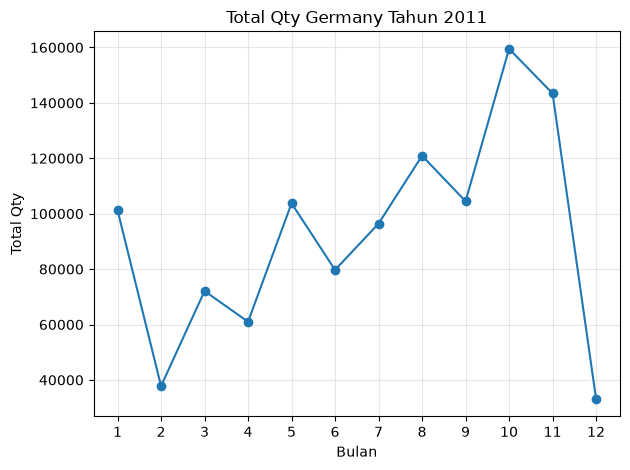

In [4]:
import matplotlib.pyplot as plt

plt.plot(TotalQty.index, TotalQty["TotalQty"], marker="o")

plt.xlabel("Bulan")
plt.ylabel("Total Qty")
plt.title("Total Qty Germany Tahun 2011")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Nomor 5 — Memprediksi total Qty Januari 2012 dengan Linear Regression

In [5]:
import numpy as np
from sklearn.linear_model import LinearRegression

x = TotalQty.index.to_numpy().reshape(-1, 1)
y = TotalQty["TotalQty"].to_numpy()

model = LinearRegression()
model.fit(x, y)

bulan_prediksi = np.array([[13]])
PredictedQty = model.predict(bulan_prediksi)[0]

print(f"Prediksi total Qty Januari 2012: {PredictedQty:.2f}")

Prediksi total Qty Januari 2012: 117751.76


## Kesimpulan

Praktikum ini menerapkan predictive mining pada data transaksi negara
Germany tahun 2011 untuk memprediksi total Qty Januari 2012. Data
disaring berdasarkan negara dan tahun, kemudian Qty dijumlahkan untuk
setiap bulan dan divisualisasikan agar pergerakannya dapat diamati.
Linear Regression digunakan untuk mempelajari hubungan antara urutan
bulan dan total Qty, dengan Januari 2012 dinyatakan sebagai bulan
ke-13. Hasil prediksi merupakan perkiraan berdasarkan tren linear
data historis, sehingga ketepatannya perlu dievaluasi dengan
membandingkannya terhadap data aktual Januari 2012 ketika tersedia.